# Three follow-up checks

The main question is whether highly rated users remain overrepresented when compared with users of similar observed tenure and recent activity. This notebook combines worked examples with outputs from `scripts/flagship_checks.py`; that script contains the complete event-by-event calculation. Run `python scripts/reproduce.py` first.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'outputs' / 'flagship'
matched = pd.read_csv(OUT / 'matched_target_choice.csv')
rewired = pd.read_csv(OUT / 'degree_preserving_null.csv')
evolution = pd.read_csv(OUT / 'structural_evolution.csv')
metadata = json.loads((OUT / 'metadata.json').read_text())


## 1. Compare users with similar opportunity

At each positive rating, the script looks **before** that rating. It groups possible recipients by time since their first observed positive rating and by the number of positive ratings they gave or received in the previous 90 days. It compares the actual recipient with eligible users in the same two groups. The chosen recipient is included in the possible recipients. A ratio above 1 means the degree group received more ratings than equal choice within those matched groups predicts. Observed tenure and activity are only rough proxies for opportunity; they do not measure platform visibility or actual trades.


,prior_positive_in_degree,observed_target_events,matched_null_expected_events,observed_over_expected
0,0,601,156.234,3.847
1,1,3087,3346.705,0.922
2,2-3,3710,4797.392,0.773
3,4-7,4117,5486.153,0.750
4,8-15,4198,5158.026,0.814
5,16-31,3986,3623.942,1.100
6,32+,7294,4424.548,1.649


Existing-target events covered: 26993
Coverage: 99.48 %


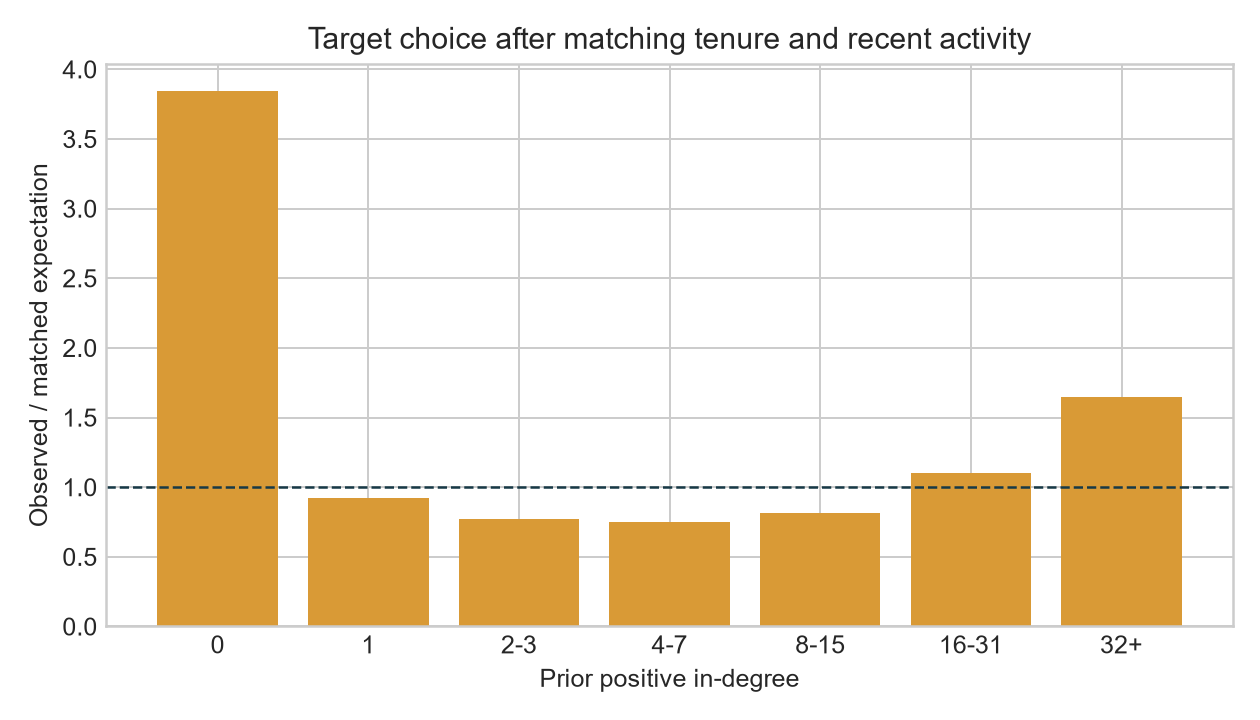

In [2]:
display(matched.round(3))
print('Existing-target events covered:', metadata['matched_choice']['matched_events'])
print('Coverage:', round(100 * metadata['matched_choice']['coverage_of_existing_target_events'], 2), '%')
display(Image(filename=str(OUT / 'matched_target_choice.png')))


The 32+ degree ratio changes from 12.70 under the earlier uniform benchmark to about 1.65 here. That large change shows the uniform benchmark is sensitive to differences in observed tenure and recent activity; it does not measure their causal contribution. The remaining association is still observational. The degree-zero group also has an elevated ratio, so the relationship is not a simple straight-line growth law. Notebook 05 shows that most degree-zero events return an earlier rating, and separates the effects of tenure and activity.


### Work one matched candidate set

The next table is **invented for teaching**. Assume these seven recipients already passed the basic eligibility rules: each was observed earlier, none is the rater, and none was previously rated positively by that rater. The values describe the moment **before** the new rating. C is the chosen recipient.

C's first observed positive rating was 40 days earlier, and C gave or received four positive ratings in the preceding 90 days. C is therefore in the **under-90-day tenure group** and the **3–9 recent-ratings group**. Keep eligible recipients in those same groups. H is excluded by tenure; I is excluded by recent activity. The remaining five include C itself, as required by the benchmark.

In [3]:
import numpy as np

example_candidates = pd.DataFrame([
    ('C', 2, 40, 4), ('D', 1, 50, 6), ('E', 3, 20, 5),
    ('F', 0, 10, 3), ('G', 1, 60, 4),
    ('H', 15, 400, 5), ('I', 8, 55, 10),
], columns=['user', 'prior_in_degree', 'observed_tenure_days', 'prior_90_day_activity'])
example_candidates['tenure_group'] = pd.cut(
    example_candidates.observed_tenure_days,
    bins=[0, 90, 365, np.inf], right=False,
    labels=['under 90', '90–364', '365+'],
)
example_candidates['activity_group'] = pd.cut(
    example_candidates.prior_90_day_activity,
    bins=[0, 1, 3, 10, np.inf], right=False,
    labels=['0', '1–2', '3–9', '10+'],
)
chosen = example_candidates.set_index('user').loc['C']
same_groups = (
    (example_candidates.tenure_group == chosen.tenure_group)
    & (example_candidates.activity_group == chosen.activity_group)
)
matched_candidates = example_candidates[same_groups]
display(example_candidates)
display(matched_candidates)

# The full analysis requires at least five matched candidates.
assert len(matched_candidates) >= 5
expected_degree_2_to_3 = matched_candidates.prior_in_degree.between(2, 3).mean()
observed_degree_2_to_3 = int(2 <= chosen.prior_in_degree <= 3)
print('Matched expected count for the 2–3 group:', expected_degree_2_to_3)
print('Observed / expected for this event:', observed_degree_2_to_3 / expected_degree_2_to_3)
assert np.isclose(expected_degree_2_to_3, 2 / 5)

,user,prior_in_degree,observed_tenure_days,prior_90_day_activity,tenure_group,activity_group
0,C,2,40,4,under 90,3–9
1,D,1,50,6,under 90,3–9
2,E,3,20,5,under 90,3–9
3,F,0,10,3,under 90,3–9
4,G,1,60,4,under 90,3–9
5,H,15,400,5,365+,3–9
6,I,8,55,10,under 90,10+


,user,prior_in_degree,observed_tenure_days,prior_90_day_activity,tenure_group,activity_group
0,C,2,40,4,under 90,3–9
1,D,1,50,6,under 90,3–9
2,E,3,20,5,under 90,3–9
3,F,0,10,3,under 90,3–9
4,G,1,60,4,under 90,3–9


Matched expected count for the 2–3 group: 0.4
Observed / expected for this event: 2.5


Two of the five matched recipients have prior degree 2–3. The expected count for that group is therefore $2/5=0.4$ for this event, and its observed/expected ratio is $1/0.4=2.5$. The full script sums counts and expectations across covered events. Matching is a descriptive comparison within coarse groups. Recent incoming ratings overlap with prior in-degree, so this exercise does not isolate a causal effect of popularity.

## 2. Keep every user's degree, randomize the links

A degree-preserving rewire swaps endpoints of two links while keeping each user's number of links fixed. The script repeats this for eight seeds, with ten successful swaps per original link. If observed clustering exceeds these rewired versions, the degree sequence alone does not explain all the observed triangles. This comparison uses the **undirected network of positive ratings**, so it does not retain rating direction or sign.


,network,seed,transitivity,edges
0,observed,-1,0.0570,18591
1,degree_preserving_rewire,2026,0.0439,18591
2,degree_preserving_rewire,2027,0.0440,18591
3,degree_preserving_rewire,2028,0.0432,18591
4,degree_preserving_rewire,2029,0.0438,18591
5,degree_preserving_rewire,2030,0.0431,18591
6,degree_preserving_rewire,2031,0.0420,18591
7,degree_preserving_rewire,2032,0.0436,18591
8,degree_preserving_rewire,2033,0.0407,18591


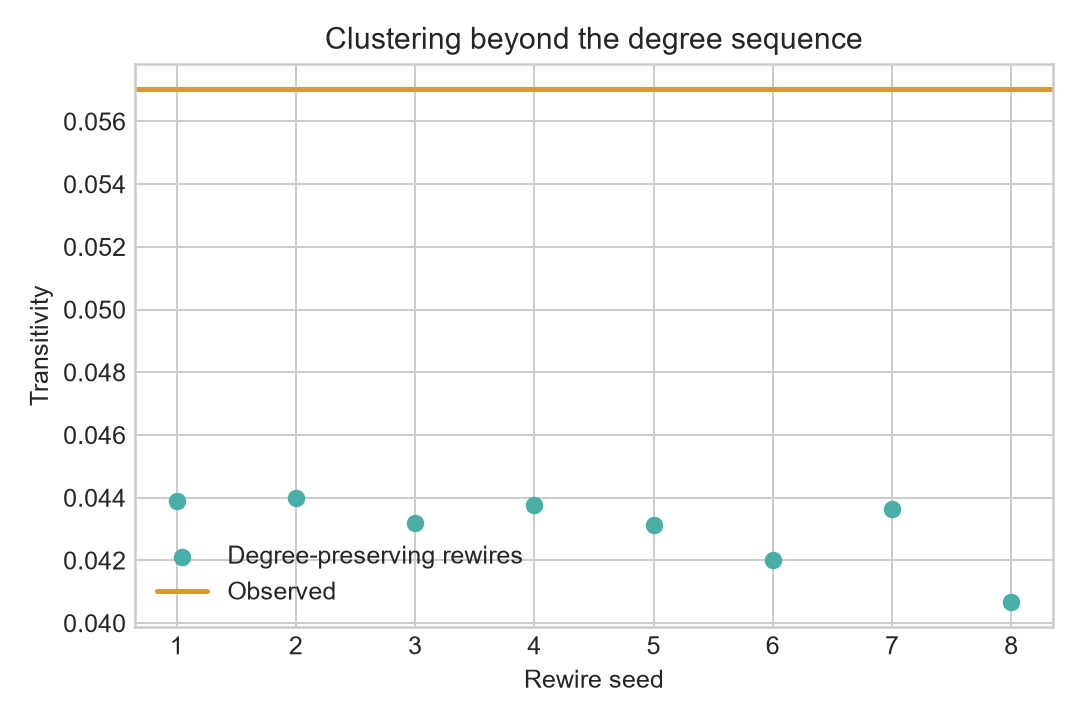

In [4]:
display(rewired.round(4))
display(Image(filename=str(OUT / 'degree_preserving_null.png')))


### Verify degree preservation on an invented graph

The toy graph below has two triangles. Swapping link endpoints changes which users are linked while preserving how many links each user has. The table and assertion check the preservation directly. Ten swaps on a small example illustrate the operation; they do not provide the full analysis's null distribution.

In [5]:
import networkx as nx

example_graph = nx.Graph([
    ('A', 'B'), ('B', 'C'), ('C', 'A'), ('C', 'D'),
    ('D', 'E'), ('E', 'F'), ('F', 'D'), ('A', 'F'),
])
example_rewired = example_graph.copy()
nx.double_edge_swap(example_rewired, nswap=10, max_tries=1000, seed=2026)
display(pd.DataFrame({
    'original_degree': dict(example_graph.degree()),
    'rewired_degree': dict(example_rewired.degree()),
}))
print('Original links:', sorted(example_graph.edges()))
print('Rewired links:', sorted(example_rewired.edges()))
print('Original transitivity:', nx.transitivity(example_graph))
print('Rewired transitivity:', nx.transitivity(example_rewired))
assert dict(example_graph.degree()) == dict(example_rewired.degree())
assert example_graph.number_of_edges() == example_rewired.number_of_edges()

,original_degree,rewired_degree
A,3,3
B,2,2
C,3,3
D,3,3
E,2,2
F,3,3


Original links: [('A', 'B'), ('A', 'C'), ('A', 'F'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('D', 'F'), ('E', 'F')]
Rewired links: [('A', 'B'), ('A', 'C'), ('A', 'F'), ('B', 'F'), ('C', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F')]
Original transitivity: 0.42857142857142855
Rewired transitivity: 0.42857142857142855


## 3. Watch network shape change

Each year-end graph keeps all positive ratings recorded so far. Largest-component share and transitivity are calculated on the undirected network of positive ratings; reciprocity uses the directed network of positive ratings. These are changes in the **cumulative record**, not proof that old ratings were still active at that date. The observed-user denominator differs from the full 5,881-user graph, which includes users never seen in a positive rating.


,year_end,active_users,directed_positive_ratings,positive_projection_edges,largest_component_share_of_active,projection_transitivity,directed_reciprocity
0,2011,1631,7745,4339,0.9963,0.0460,0.8795
1,2012,3116,16367,9386,0.9981,0.0539,0.8531
2,2013,4991,27505,15890,0.9964,0.0485,0.8446
3,2014,5455,31060,18032,0.9963,0.0549,0.8389
4,2015,5571,31989,18571,0.9961,0.0569,0.8389


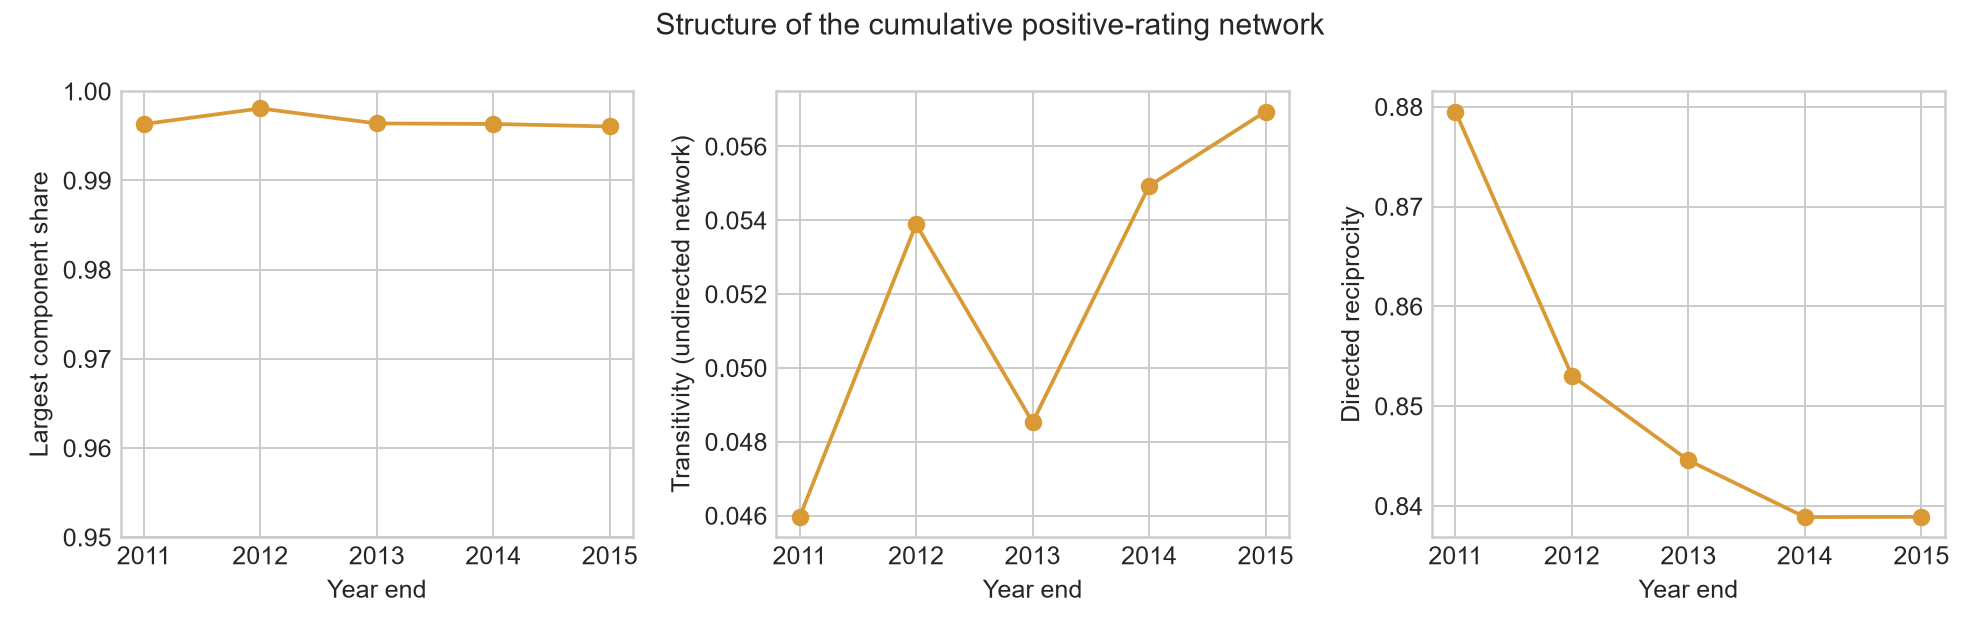

In [6]:
display(evolution.round(4))
display(Image(filename=str(OUT / 'structural_evolution.png')))


## What can we conclude?

The observed graph has more transitivity than the eight degree-preserving rewires. Its reciprocity falls across the 2011–2015 cumulative snapshots, while transitivity rises overall with a 2013 dip. Highly rated users remain overrepresented after coarse matching, but the ratio is far smaller than under uniform choice. None of these comparisons identifies a causal mechanism for how raters chose users.
